### Stage 1: are frozen TimeSformer features of the best exo view at 8 FPS any good for proficiency?

Proposed pipeline: 8 FPS windows of the best exo camera -> frozen TimeSformer -> SmolLM-135M fine-tuned to predict the
proficiency score and the proficiency.why. The LM can only use what the frozen encoder captures, so stage 1 tests the
encoder alone with the evaluation used so far, and gates the rest.

* **Encoder**: `facebook/timesformer-base-finetuned-k600` (frozen, fp16), 8-frame clips at 8 FPS = 1 s, back-to-back
  over the whole take (~148k clips). Two framings: **squash** (whole 16:9 frame resized to 224x224) and **crop**
  (shortest edge 224, center crop: the processor default, which cuts the sides). Layers 6 and 12.
* **Take features** (each scenario-centered, PCA-64 inside the fold): **CLS**, **mean** patch token, **token std**
  (spread over the 8x196 patch tokens), **temporal std** (clip-to-clip spread of the mean token over the take), and
  **all** four.
* **References in the same folds**: zero-shot Qwen3.5-4B exo (best_exo, 1 FPS tiles) mean and token std, layers 8 / 16
  (from `pooling.ipynb`'s caches); duration only.
* **Evaluation**: 4 x 5-fold CV split by participant (the same folds as before), logistic regression (accuracy) and ridge
  (within-scenario Spearman with level, predictions centered within fold and scenario), participant bootstrap.

**Gate (fixed before running)**: continue to stage 2 only if the best TimeSformer representation reaches the Qwen exo
level, within-scenario Spearman >= 0.35.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
import gc

import torch
from scipy.stats import spearmanr
from tqdm.auto import tqdm

EMBEDDING_DIR = Path("embeddings")
all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
SCENARIO_NAMES = np.unique(scenarios)
log_duration = np.log([clip_of[t]["seconds"] for t in names])

# TimeSformer: per clip (2 layers, [CLS, patch mean, patch std], 768).
ts = torch.load(EMBEDDING_DIR / "timesformer_k600_exo8fps_clips.pt")
TS_LAYERS = {6: 0, 12: 1}
features = {}
for variant, clips in ts["clips"].items():
    for layer, li in TS_LAYERS.items():
        per_take = [clips[t][:, li].float() for t in names]
        features[f"TimeSformer {variant}, L{layer}", "CLS"] = np.stack([x[:, 0].mean(0).numpy() for x in per_take])
        features[f"TimeSformer {variant}, L{layer}", "mean"] = np.stack([x[:, 1].mean(0).numpy() for x in per_take])
        features[f"TimeSformer {variant}, L{layer}", "token std"] = np.stack([x[:, 2].mean(0).numpy() for x in per_take])
        features[f"TimeSformer {variant}, L{layer}", "temporal std"] = np.stack(
            [x[:, 1].std(0).numpy() if len(x) > 1 else np.zeros(x.shape[-1], np.float32) for x in per_take])
n_clips = np.array([len(ts["clips"]["squash"][t]) for t in names])
print(f"TimeSformer: {n_clips.sum()} clips per framing ({np.median(n_clips):.0f} per take); cameras "
      f"{Counter(ts['camera'][t] for t in names).most_common(4)}")
del ts
gc.collect()

# Qwen3.5-4B exo references (pooling.ipynb's cache): mean and token std of the 1 FPS tiles.
qwen = torch.load(EMBEDDING_DIR / "qwen35_base_exo_tiles1fps_readout.pt")["windows"]
for layer, li in {8: 0, 16: 1}.items():
    means, stds = [], []
    for t in names:
        ws = [qwen[t][k] for k in sorted(qwen[t])]
        means.append(torch.stack([w["temporal"][li].float().mean(0) for w in ws]).mean(0).numpy())
        stds.append(torch.stack([w["std"][li].float() for w in ws]).mean(0).numpy())
    features[f"Qwen exo 1 FPS, L{layer}", "mean"] = np.stack(means)
    features[f"Qwen exo 1 FPS, L{layer}", "token std"] = np.stack(stds)
del qwen
gc.collect()

TS_REPS = ["CLS", "mean", "token std", "temporal std"]
REPRESENTATIONS = {}
for source in sorted({s for s, _ in features if s.startswith("TimeSformer")}):
    for rep in TS_REPS:
        REPRESENTATIONS[f"{source}: {rep}"] = [(source, rep)]
    REPRESENTATIONS[f"{source}: all"] = [(source, rep) for rep in TS_REPS]
for layer in (8, 16):
    REPRESENTATIONS[f"Qwen exo 1 FPS, L{layer}: mean"] = [(f"Qwen exo 1 FPS, L{layer}", "mean")]
    REPRESENTATIONS[f"Qwen exo 1 FPS, L{layer}: mean + token std"] = [(f"Qwen exo 1 FPS, L{layer}", r) for r in ("mean", "token std")]
REPRESENTATIONS["TimeSformer squash, L12: all + Qwen exo L8: mean + token std"] = (
    REPRESENTATIONS["TimeSformer squash, L12: all"] + REPRESENTATIONS["Qwen exo 1 FPS, L8: mean + token std"])
print(f"{len(REPRESENTATIONS)} representations")

TimeSformer: 147085 clips per framing (56 per take); cameras [('cam03', 418), ('cam01', 341), ('cam02', 253), ('cam04', 116)]


25 representations


In [3]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

N_REPEATS, N_FOLDS, PCA_DIMS = 4, 5, 64

def centered(X, keys, fit):
    fit_rows = np.zeros(len(X), bool)
    fit_rows[fit] = True
    overall = X[fit_rows].mean(0)
    means = {k: X[fit_rows & (keys == k)].mean(0) if (fit_rows & (keys == k)).any() else overall for k in np.unique(keys)}
    return X - np.stack([means[k] for k in keys])

def make_probe():
    return make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))

hits = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
continuous = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
fold_of = np.zeros((N_REPEATS, len(names)), int)
for repeat in range(N_REPEATS):
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(tqdm(list(folds), desc=f"repeat {repeat + 1}")):
        fold_of[repeat, held] = fold
        onehot = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None]).transform(scenarios[:, None]).toarray()

        def run(key, X_features):
            X = np.hstack([onehot, X_features])
            hits[key][repeat, held] = make_probe().fit(X[fit], scores[fit]).predict(X[held]) == scores[held]
            ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 6, 17))).fit(X[fit], scores[fit])
            continuous[key][repeat, held] = ridge.predict(X[held])

        run("scenario only", np.zeros((len(names), 0)))
        duration = centered(log_duration[:, None], scenarios, fit)
        run("duration only", np.hstack([duration * (scenarios == s)[:, None] for s in SCENARIO_NAMES]))
        blocks = {}
        def block(key):
            if key not in blocks:
                X = centered(features[key], scenarios, fit)
                blocks[key] = PCA(PCA_DIMS, svd_solver="full").fit(X[fit]).transform(X)
            return blocks[key]
        for key, parts in REPRESENTATIONS.items():
            run(key, np.hstack([block(p) for p in parts]))
print(f"{len(hits)} representations x {N_REPEATS} repeats x {len(names)} takes")

repeat 1:   0%|          | 0/5 [00:00<?, ?it/s]

repeat 2:   0%|          | 0/5 [00:00<?, ?it/s]

repeat 3:   0%|          | 0/5 [00:00<?, ?it/s]

repeat 4:   0%|          | 0/5 [00:00<?, ?it/s]

27 representations x 4 repeats x 1338 takes


In [4]:
N_BOOTSTRAP = 500
unique_participants = np.unique(participants)
rows_of = {p: np.flatnonzero(participants == p) for p in unique_participants}
boot = np.random.default_rng(0)
resamples = [np.concatenate([rows_of[p] for p in boot.choice(unique_participants, len(unique_participants))])
             for _ in range(N_BOOTSTRAP)]

def scenario_centered(values):
    out = values.astype(float).copy()
    for s in SCENARIO_NAMES:
        out[scenarios == s] -= values[scenarios == s].mean()
    return out

level_centered = scenario_centered(scores)

def within_fold_centered(c):
    out = c.copy()
    for r in range(N_REPEATS):
        for fold in np.unique(fold_of[r]):
            for s in SCENARIO_NAMES:
                group = (fold_of[r] == fold) & (scenarios == s)
                out[r, group] -= c[r, group].mean()
    return out.mean(0)

ordinal = {key: within_fold_centered(c) for key, c in continuous.items()}
per_take = {key: h.mean(0) for key, h in hits.items()}

def rho(key, rows):
    a = ordinal[key][rows]
    return spearmanr(a, level_centered[rows])[0] if np.std(a) > 1e-9 else 0.0

ALL = np.ones(len(names), bool)
def with_ci(key, rows=ALL, n=N_BOOTSTRAP):
    return rho(key, rows), *np.quantile([rho(key, r[rows[r]]) for r in resamples[:n]], [0.025, 0.975])

def accuracy(key):
    return per_take[key].mean(), *np.quantile([per_take[key][r].mean() for r in resamples], [0.025, 0.975])

spearman = {key: with_ci(key) for key in ordinal}
print(f"{'representation':<64}{'Spearman with level':>28}{'accuracy':>26}")
for key in ["scenario only", "duration only", *REPRESENTATIONS]:
    s, a = spearman[key], accuracy(key)
    print(f"{key:<64}{s[0]:>+10.3f} [{s[1]:+.3f}, {s[2]:+.3f}]{a[0]:>10.3f} [{a[1]:.3f}, {a[2]:.3f}]")

ts_keys = [k for k in REPRESENTATIONS if k.startswith("TimeSformer") and "Qwen" not in k]
best = max(ts_keys, key=lambda k: spearman[k][0])
reference = "Qwen exo 1 FPS, L16: mean"
diff = np.array([rho(best, r) - rho(reference, r) for r in resamples])
GATE = 0.35
passed = spearman[best][0] >= GATE
print(f"\nBest TimeSformer representation (of {len(ts_keys)}): {best}  Spearman {spearman[best][0]:+.3f} "
      f"[{spearman[best][1]:+.3f}, {spearman[best][2]:+.3f}]")
print(f"  minus {reference}: {spearman[best][0] - spearman[reference][0]:+.3f} "
      f"[{np.quantile(diff, 0.025):+.3f}, {np.quantile(diff, 0.975):+.3f}]  (best-of-{len(ts_keys)} is optimistic)")
print(f"GATE (Spearman >= {GATE}): {'PASS' if passed else 'FAIL'}")

representation                                                           Spearman with level                  accuracy
scenario only                                                       +0.000 [+0.000, +0.000]     0.400 [0.324, 0.481]
duration only                                                       +0.236 [+0.142, +0.326]     0.394 [0.333, 0.455]
TimeSformer crop, L12: CLS                                          +0.397 [+0.262, +0.502]     0.462 [0.400, 0.528]
TimeSformer crop, L12: mean                                         +0.369 [+0.241, +0.481]     0.444 [0.381, 0.517]
TimeSformer crop, L12: token std                                    +0.459 [+0.326, +0.572]     0.473 [0.412, 0.546]
TimeSformer crop, L12: temporal std                                 +0.369 [+0.236, +0.467]     0.456 [0.405, 0.514]
TimeSformer crop, L12: all                                          +0.406 [+0.274, +0.510]     0.449 [0.392, 0.508]
TimeSformer crop, L6: CLS                                     


Best TimeSformer representation (of 20): TimeSformer squash, L12: token std  Spearman +0.464 [+0.332, +0.575]
  minus Qwen exo 1 FPS, L16: mean: +0.114 [+0.045, +0.189]  (best-of-20 is optimistic)
GATE (Spearman >= 0.35): PASS


In [5]:
# Per scenario (point estimates).
KEYS = ["duration only", "Qwen exo 1 FPS, L16: mean", "Qwen exo 1 FPS, L8: mean + token std",
        "TimeSformer squash, L12: all", "TimeSformer crop, L12: all", "TimeSformer squash, L6: all", best,
        "TimeSformer squash, L12: all + Qwen exo L8: mean + token std"]
KEYS = list(dict.fromkeys(KEYS))
print(f"{'representation':<64}" + "".join(f"{f'{s[:11]} ({(scenarios == s).sum()})':>18}" for s in SCENARIO_NAMES))
for key in KEYS:
    print(f"{key:<64}" + "".join(f"{rho(key, scenarios == s):>+18.2f}" for s in SCENARIO_NAMES))

representation                                                    Basketball (379)      Cooking (91)       Dance (290)       Music (118) Rock Climbi (413)       Soccer (47)
duration only                                                                +0.23             +0.40             +0.25             -0.02             +0.29             -0.41
Qwen exo 1 FPS, L16: mean                                                    +0.44             +0.22             +0.15             -0.18             +0.54             -0.20
Qwen exo 1 FPS, L8: mean + token std                                         +0.53             +0.42             +0.18             -0.18             +0.57             -0.11
TimeSformer squash, L12: all                                                 +0.58             +0.15             +0.18             -0.23             +0.61             +0.24
TimeSformer crop, L12: all                                                   +0.54             +0.23             +0.14             -0.0

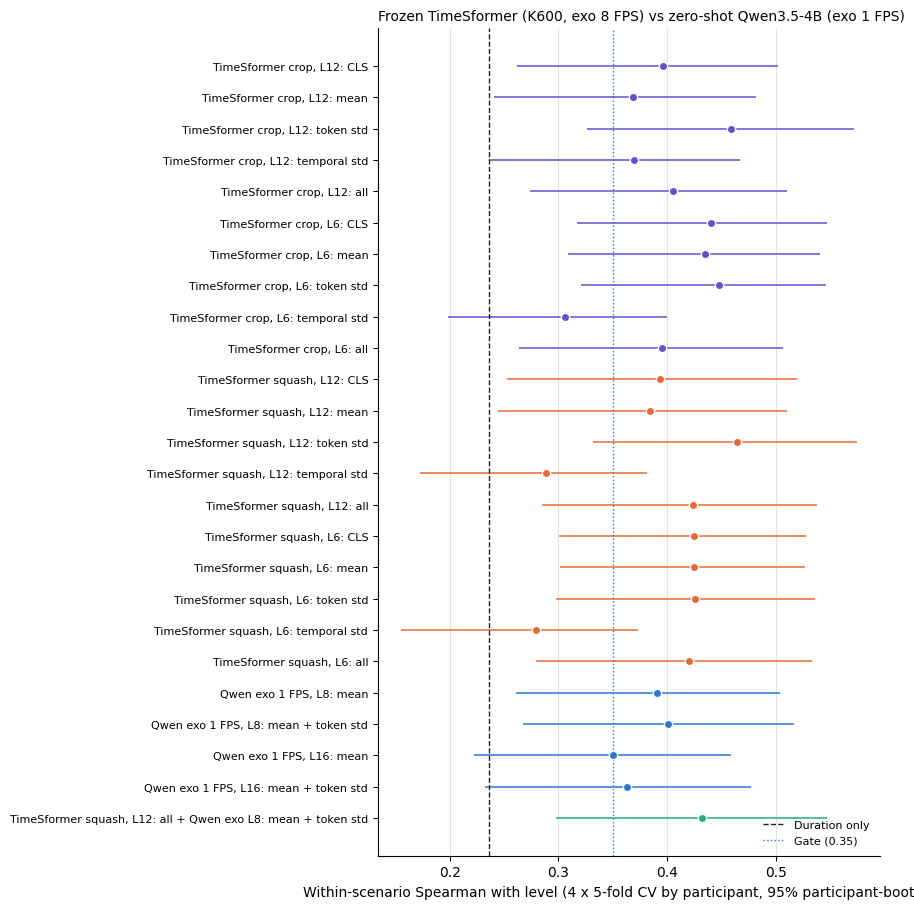

In [6]:
import matplotlib.pyplot as plt

GRID_COLOR, DARK = "#e4e3df", "#1f1f1d"
COLORS = {"TimeSformer squash": "#eb6834", "TimeSformer crop": "#6250d6", "Qwen": "#2a78d6", "both": "#1baf7a"}
keys = [k for k in REPRESENTATIONS]
color = [COLORS["both"] if "+ Qwen" in k else COLORS["Qwen"] if k.startswith("Qwen") else
         COLORS["TimeSformer squash"] if "squash" in k else COLORS["TimeSformer crop"] for k in keys]
values = np.array([spearman[k] for k in keys])
fig, ax = plt.subplots(figsize=(9, 0.32 * len(keys) + 1.2))
y = np.arange(len(keys))[::-1]
for yy, v, c in zip(y, values, color):
    ax.errorbar(v[0], yy, xerr=[[v[0] - v[1]], [v[2] - v[0]]], fmt="o", ms=6, color=c, markeredgecolor="white",
                markeredgewidth=1, elinewidth=1.1)
ax.axvline(spearman["duration only"][0], color=DARK, lw=1, ls="--", label="Duration only")
ax.axvline(GATE, color=COLORS["Qwen"], lw=1, ls=":", label=f"Gate ({GATE})")
ax.set_yticks(y, keys, fontsize=8)
ax.set_xlabel("Within-scenario Spearman with level\n(4 x 5-fold CV by participant; 95% participant bootstrap)")
ax.set_title("Frozen TimeSformer (K600, exo 8 FPS) vs zero-shot Qwen3.5-4B (exo 1 FPS)", loc="left", fontsize=10)
ax.grid(axis="x", color=GRID_COLOR, lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig("figures/timesformer_stage1.png", dpi=200, bbox_inches="tight")
plt.show()